In [1]:
import warnings
warnings.filterwarnings("ignore")

import json, os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib

from sklearn.model_selection import train_test_split, RandomizedSearchCV, StratifiedKFold
from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                              roc_auc_score, log_loss, classification_report,
                              ConfusionMatrixDisplay, RocCurveDisplay)
from xgboost import XGBClassifier

RANDOM_SEED = 42
np.random.seed(RANDOM_SEED)

DATA_DIR = "../data"
MODEL_DIR = "../models"
DASHBOARD_DIR = "../dashboard"

TRAIN_PATH = f"{DATA_DIR}/train.csv"
TEST_PATH = f"{DATA_DIR}/test.csv"
SAMPLE_SUB_PATH = f"{DATA_DIR}/sample_submission.csv"

os.makedirs(MODEL_DIR, exist_ok=True)
os.makedirs(DASHBOARD_DIR, exist_ok=True)

In [2]:
df = pd.read_csv(TRAIN_PATH)
test_df = pd.read_csv(TEST_PATH)
sample_sub = pd.read_csv(SAMPLE_SUB_PATH)

print("train:", df.shape, "| test:", test_df.shape, "| sample_submission:", sample_sub.shape)
df.head()

train: (58592, 44) | test: (39063, 43) | sample_submission: (39063, 2)


,policy_id,policy_tenure,age_of_car,age_of_policyholder,area_cluster,population_density,make,segment,model,fuel_type,...,is_brake_assist,is_power_door_locks,is_central_locking,is_power_steering,is_driver_seat_height_adjustable,is_day_night_rear_view_mirror,is_ecw,is_speed_alert,ncap_rating,is_claim
0,ID00001,0.515874,0.05,0.644231,C1,4990,1,A,M1,CNG,...,No,No,No,Yes,No,No,No,Yes,0,0
1,ID00002,0.672619,0.02,0.375000,C2,27003,1,A,M1,CNG,...,No,No,No,Yes,No,No,No,Yes,0,0
2,ID00003,0.841110,0.02,0.384615,C3,4076,1,A,M1,CNG,...,No,No,No,Yes,No,No,No,Yes,0,0
3,ID00004,0.900277,0.11,0.432692,C4,21622,1,C1,M2,Petrol,...,Yes,Yes,Yes,Yes,Yes,Yes,Yes,Yes,2,0
4,ID00005,0.596403,0.11,0.634615,C5,34738,2,A,M3,Petrol,...,No,Yes,Yes,Yes,No,Yes,Yes,Yes,2,0


In [3]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 58592 entries, 0 to 58591
Data columns (total 44 columns):
 #   Column                            Non-Null Count  Dtype  
---  ------                            --------------  -----  
 0   policy_id                         58592 non-null  object 
 1   policy_tenure                     58592 non-null  float64
 2   age_of_car                        58592 non-null  float64
 3   age_of_policyholder               58592 non-null  float64
 4   area_cluster                      58592 non-null  object 
 5   population_density                58592 non-null  int64  
 6   make                              58592 non-null  int64  
 7   segment                           58592 non-null  object 
 8   model                             58592 non-null  object 
 9   fuel_type                         58592 non-null  object 
 10  max_torque                        58592 non-null  object 
 11  max_power                         58592 non-null  object 
 12  engi

In [4]:
df.describe(include='all').T

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
policy_id,58592,58592,ID00001,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN
policy_tenure,58592.0,NaN,NaN,NaN,0.611246,0.414156,0.002735,0.21025,0.573792,1.039104,1.396641
age_of_car,58592.0,NaN,NaN,NaN,0.069424,0.056721,0.0,0.02,0.06,0.11,1.0
age_of_policyholder,58592.0,NaN,NaN,NaN,0.46942,0.122886,0.288462,0.365385,0.451923,0.548077,1.0
area_cluster,58592,22,C8,13654,NaN,NaN,NaN,NaN,NaN,NaN,NaN
population_density,58592.0,NaN,NaN,NaN,18826.858667,17660.174792,290.0,6112.0,8794.0,27003.0,73430.0
make,58592.0,NaN,NaN,NaN,1.763722,1.136988,1.0,1.0,1.0,3.0,5.0
segment,58592,6,B2,18314,NaN,NaN,NaN,NaN,NaN,NaN,NaN
model,58592,11,M1,14948,NaN,NaN,NaN,NaN,NaN,NaN,NaN
fuel_type,58592,3,Petrol,20532,NaN,NaN,NaN,NaN,NaN,NaN,NaN


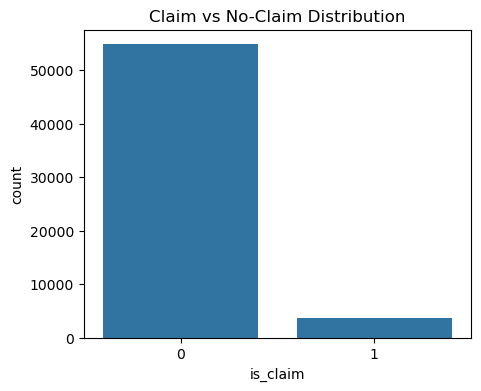

is_claim
0    0.936032
1    0.063968
Name: proportion, dtype: float64


In [5]:
plt.figure(figsize=(5,4))
sns.countplot(x="is_claim", data=df)
plt.title("Claim vs No-Claim Distribution")
plt.savefig(f"{DASHBOARD_DIR}/class_balance.png", bbox_inches="tight")
plt.show()

print(df["is_claim"].value_counts(normalize=True))

In [6]:
missing = df.isnull().mean().sort_values(ascending=False)
missing = missing[missing > 0]
print(missing)

if len(missing) > 0:
    plt.figure(figsize=(8, max(4, len(missing)*0.3)))
    missing.plot(kind="barh")
    plt.title("Missing Value Proportion by Column")
    plt.savefig(f"{DASHBOARD_DIR}/missing_values.png", bbox_inches="tight")
    plt.show()

Series([], dtype: float64)


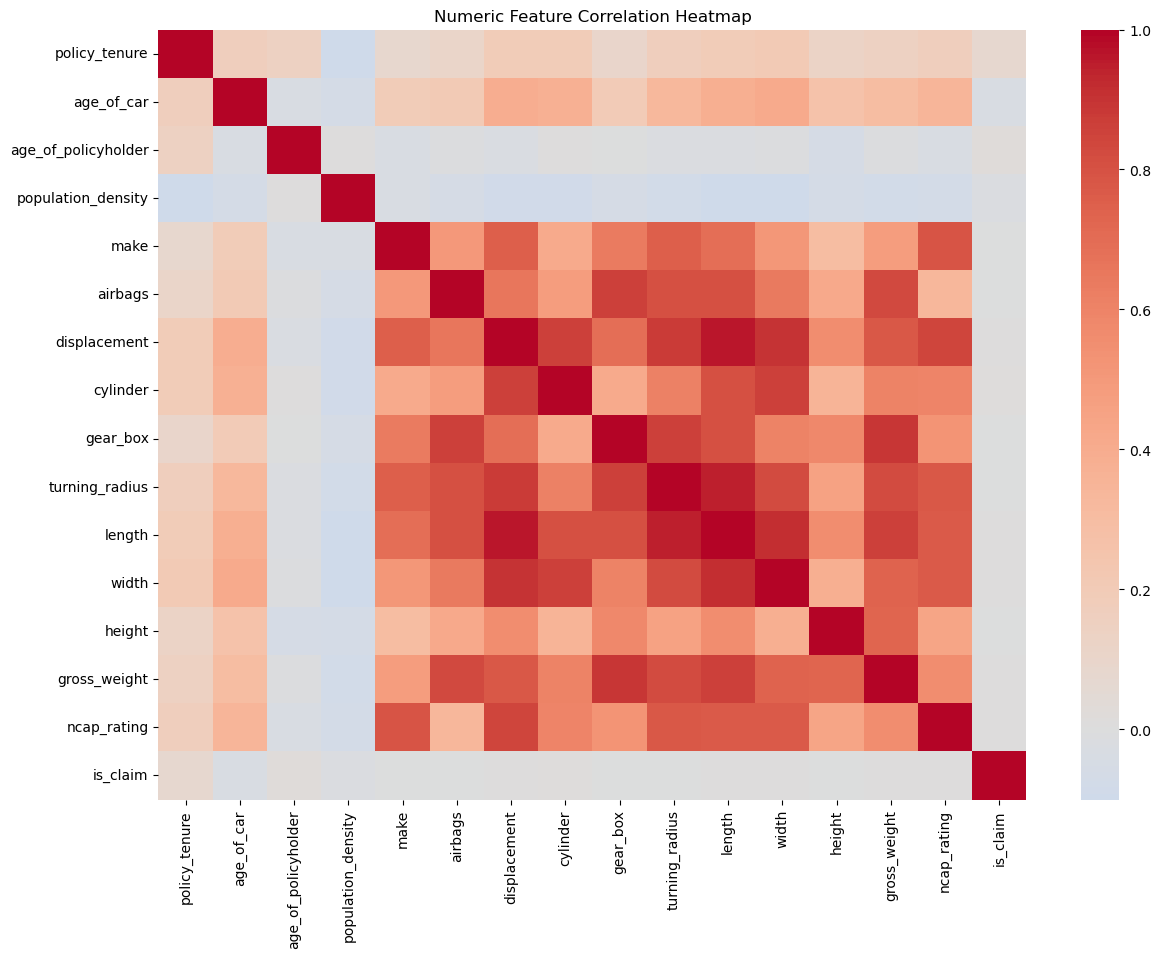

In [7]:
numeric_df = df.select_dtypes(include=[np.number])
plt.figure(figsize=(14, 10))
sns.heatmap(numeric_df.corr(), cmap="coolwarm", center=0)
plt.title("Numeric Feature Correlation Heatmap")
plt.savefig(f"{DASHBOARD_DIR}/correlation_heatmap.png", bbox_inches="tight")
plt.show()

In [8]:
def split_torque_power(data):
    data = data.copy()
    torque = data["max_torque"].str.extract(r"([\d.]+)Nm@([\d.]+)rpm")
    data["torque_nm"] = torque[0].astype(float)
    data["torque_rpm"] = torque[1].astype(float)
    power = data["max_power"].str.extract(r"([\d.]+)bhp@([\d.]+)rpm")
    data["power_bhp"] = power[0].astype(float)
    data["power_rpm"] = power[1].astype(float)
    return data.drop(columns=["max_torque", "max_power"])

df_parsed = split_torque_power(df)
test_parsed = split_torque_power(test_df)

print(df_parsed[["torque_nm", "torque_rpm", "power_bhp", "power_rpm"]].describe())

          torque_nm    torque_rpm     power_bhp     power_rpm
count  58592.000000  58592.000000  58592.000000  58592.000000
mean     134.450937   3533.176031     78.976765   5307.163094
std       73.146794    725.960661     27.699259    916.770819
min       60.000000   1750.000000     40.360000   3600.000000
25%       60.000000   2750.000000     40.360000   4000.000000
50%      113.000000   3500.000000     88.500000   6000.000000
75%      200.000000   4400.000000     97.890000   6000.000000
max      250.000000   4400.000000    118.360000   6000.000000


In [9]:
def clean_features(data, drop_target=True):
    data = data.copy()
    ids = data["policy_id"] if "policy_id" in data.columns else None
    if "policy_id" in data.columns:
        data = data.drop(columns=["policy_id"])
    y_local = None
    if drop_target and "is_claim" in data.columns:
        y_local = data["is_claim"]
        data = data.drop(columns=["is_claim"])
    return data, y_local, ids

X_raw, y, _ = clean_features(df_parsed)
X_test_raw, _, test_ids = clean_features(test_parsed, drop_target=False)

for col in X_raw.columns:
    if pd.api.types.is_numeric_dtype(X_raw[col]):
        fill_val = X_raw[col].median()
    else:
        mode = X_raw[col].mode()
        fill_val = mode.iloc[0] if not mode.empty else "unknown"
    X_raw[col] = X_raw[col].fillna(fill_val)
    if col in X_test_raw.columns:
        X_test_raw[col] = X_test_raw[col].fillna(fill_val)

encoders = {}
cat_cols = X_raw.select_dtypes(exclude=[np.number]).columns.tolist()
for col in cat_cols:
    le = LabelEncoder()
    X_raw[col] = le.fit_transform(X_raw[col].astype(str))
    known = set(le.classes_)
    X_test_raw[col] = X_test_raw[col].astype(str).apply(lambda v: v if v in known else le.classes_[0])
    X_test_raw[col] = le.transform(X_test_raw[col])
    encoders[col] = le

num_cols = X_raw.select_dtypes(include=[np.number]).columns.tolist()
scaler = StandardScaler()
X_raw[num_cols] = scaler.fit_transform(X_raw[num_cols])
X_test_raw[num_cols] = scaler.transform(X_test_raw[num_cols])

X = X_raw
X_test_final = X_test_raw[X.columns]

print("Categorical columns encoded:", cat_cols)
print("Feature matrix shape:", X.shape, "| Test feature matrix shape:", X_test_final.shape)

Categorical columns encoded: ['area_cluster', 'segment', 'model', 'fuel_type', 'engine_type', 'is_esc', 'is_adjustable_steering', 'is_tpms', 'is_parking_sensors', 'is_parking_camera', 'rear_brakes_type', 'transmission_type', 'steering_type', 'is_front_fog_lights', 'is_rear_window_wiper', 'is_rear_window_washer', 'is_rear_window_defogger', 'is_brake_assist', 'is_power_door_locks', 'is_central_locking', 'is_power_steering', 'is_driver_seat_height_adjustable', 'is_day_night_rear_view_mirror', 'is_ecw', 'is_speed_alert']
Feature matrix shape: (58592, 44) | Test feature matrix shape: (39063, 44)


In [10]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=RANDOM_SEED, stratify=y
)
print(X_train.shape, X_test.shape)

(46873, 44) (11719, 44)


In [11]:
results = {}

def evaluate_model(name, model, X_test, y_test):
    y_pred = model.predict(X_test)
    y_proba = model.predict_proba(X_test)[:, 1]

    metrics = {
        "accuracy": accuracy_score(y_test, y_pred),
        "precision": precision_score(y_test, y_pred, zero_division=0),
        "recall": recall_score(y_test, y_pred, zero_division=0),
        "f1": f1_score(y_test, y_pred, zero_division=0),
        "roc_auc": roc_auc_score(y_test, y_proba),
        "log_loss": log_loss(y_test, y_proba),
    }
    results[name] = metrics
    print(f"--- {name} ---")
    print(classification_report(y_test, y_pred, zero_division=0))
    print(metrics)

    ConfusionMatrixDisplay.from_predictions(y_test, y_pred)
    plt.title(f"Confusion Matrix - {name}")
    plt.savefig(f"{DASHBOARD_DIR}/confusion_matrix_{name}.png", bbox_inches="tight")
    plt.show()

    RocCurveDisplay.from_predictions(y_test, y_proba)
    plt.title(f"ROC Curve - {name}")
    plt.savefig(f"{DASHBOARD_DIR}/roc_curve_{name}.png", bbox_inches="tight")
    plt.show()

    return metrics

--- logistic_regression ---
              precision    recall  f1-score   support

           0       0.95      0.56      0.71     10969
           1       0.08      0.55      0.14       750

    accuracy                           0.56     11719
   macro avg       0.51      0.56      0.42     11719
weighted avg       0.89      0.56      0.67     11719

{'accuracy': 0.5641266319651848, 'precision': 0.0799922898997687, 'recall': 0.5533333333333333, 'f1': 0.13977770293027955, 'roc_auc': 0.5893601969185888, 'log_loss': 0.6731880506538029}


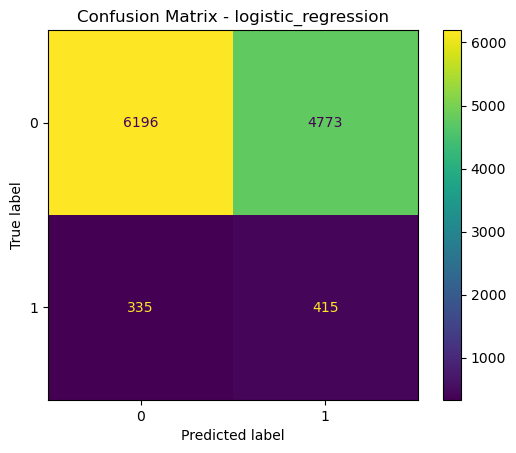

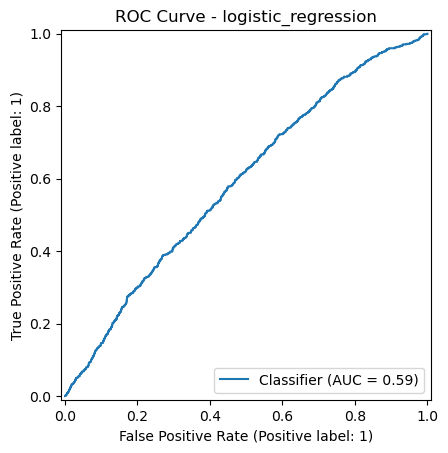

{'accuracy': 0.5641266319651848,
 'precision': 0.0799922898997687,
 'recall': 0.5533333333333333,
 'f1': 0.13977770293027955,
 'roc_auc': 0.5893601969185888,
 'log_loss': 0.6731880506538029}

In [12]:
lr = LogisticRegression(max_iter=1000, random_state=RANDOM_SEED, class_weight="balanced")
lr.fit(X_train, y_train)
evaluate_model("logistic_regression", lr, X_test, y_test)

--- decision_tree ---
              precision    recall  f1-score   support

           0       0.96      0.50      0.65     10969
           1       0.09      0.69      0.15       750

    accuracy                           0.51     11719
   macro avg       0.52      0.59      0.40     11719
weighted avg       0.90      0.51      0.62     11719

{'accuracy': 0.5094291321785135, 'precision': 0.08596985257578267, 'recall': 0.692, 'f1': 0.15293944305289525, 'roc_auc': 0.6328657732397363, 'log_loss': 0.7703930342924211}


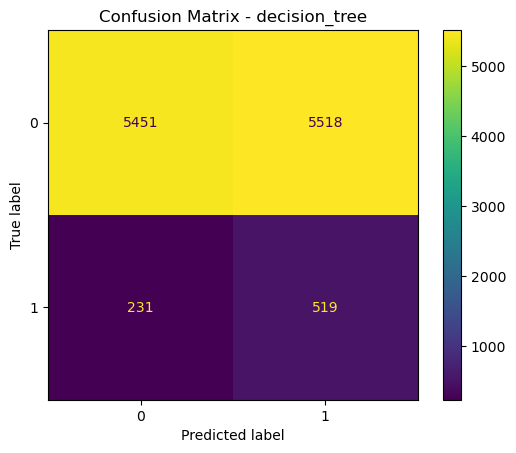

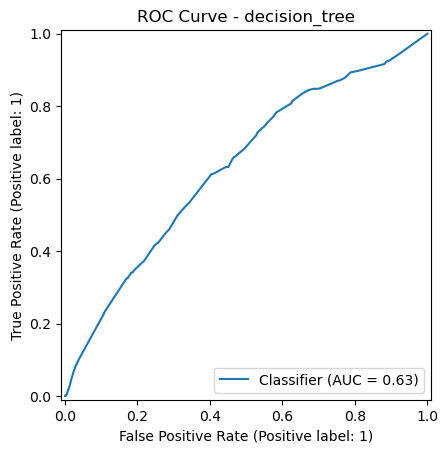

{'accuracy': 0.5094291321785135,
 'precision': 0.08596985257578267,
 'recall': 0.692,
 'f1': 0.15293944305289525,
 'roc_auc': 0.6328657732397363,
 'log_loss': 0.7703930342924211}

In [13]:
dt = DecisionTreeClassifier(random_state=RANDOM_SEED, class_weight="balanced", max_depth=8)
dt.fit(X_train, y_train)
evaluate_model("decision_tree", dt, X_test, y_test)

--- random_forest ---
              precision    recall  f1-score   support

           0       0.95      0.73      0.83     10969
           1       0.10      0.42      0.16       750

    accuracy                           0.71     11719
   macro avg       0.52      0.58      0.49     11719
weighted avg       0.89      0.71      0.78     11719

{'accuracy': 0.7132861165628467, 'precision': 0.09697344039530574, 'recall': 0.4186666666666667, 'f1': 0.15747241725175526, 'roc_auc': 0.6311568967089068, 'log_loss': 0.51144985230387}


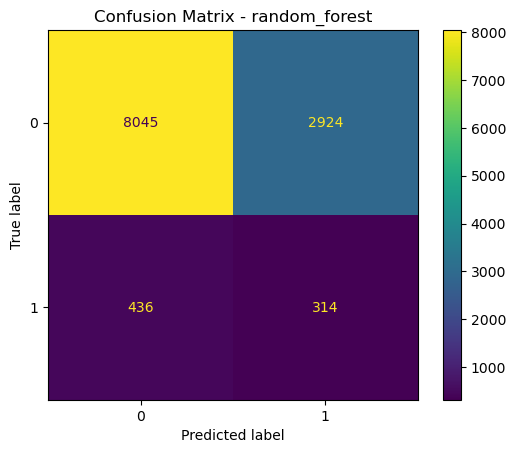

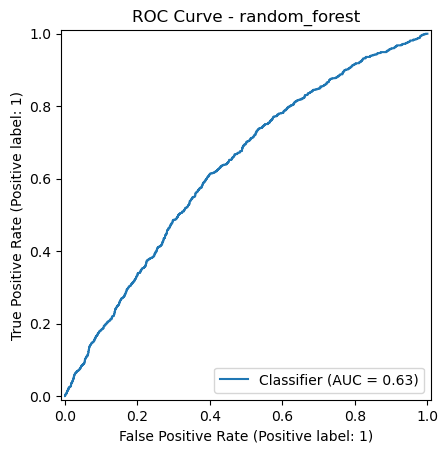

{'accuracy': 0.7132861165628467,
 'precision': 0.09697344039530574,
 'recall': 0.4186666666666667,
 'f1': 0.15747241725175526,
 'roc_auc': 0.6311568967089068,
 'log_loss': 0.51144985230387}

In [14]:
rf = RandomForestClassifier(
    n_estimators=300, max_depth=12, random_state=RANDOM_SEED,
    class_weight="balanced", n_jobs=-1
)
rf.fit(X_train, y_train)
evaluate_model("random_forest", rf, X_test, y_test)

--- xgboost ---
              precision    recall  f1-score   support

           0       0.95      0.64      0.76     10969
           1       0.10      0.56      0.16       750

    accuracy                           0.63     11719
   macro avg       0.52      0.60      0.46     11719
weighted avg       0.90      0.63      0.73     11719

{'accuracy': 0.6322211792815087, 'precision': 0.09508644222020018, 'recall': 0.5573333333333333, 'f1': 0.16245627671978236, 'roc_auc': 0.6371302762330203, 'log_loss': 0.5799905172088333}


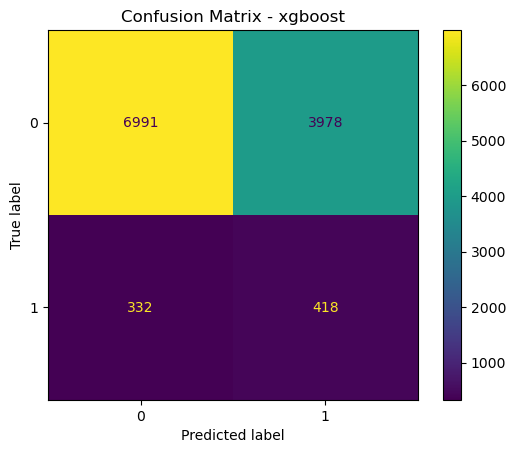

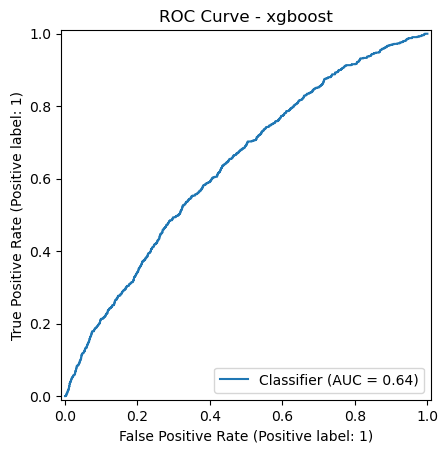

{'accuracy': 0.6322211792815087,
 'precision': 0.09508644222020018,
 'recall': 0.5573333333333333,
 'f1': 0.16245627671978236,
 'roc_auc': 0.6371302762330203,
 'log_loss': 0.5799905172088333}

In [15]:
pos_weight = (y_train == 0).sum() / max((y_train == 1).sum(), 1)
xgb = XGBClassifier(
    n_estimators=300, max_depth=6, learning_rate=0.05,
    random_state=RANDOM_SEED, scale_pos_weight=pos_weight,
    eval_metric="logloss", n_jobs=-1
)
xgb.fit(X_train, y_train)
evaluate_model("xgboost", xgb, X_test, y_test)

In [16]:
pd.DataFrame(results).T.sort_values("roc_auc", ascending=False)

,accuracy,precision,recall,f1,roc_auc,log_loss
xgboost,0.632221,0.095086,0.557333,0.162456,0.637130,0.579991
decision_tree,0.509429,0.085970,0.692000,0.152939,0.632866,0.770393
random_forest,0.713286,0.096973,0.418667,0.157472,0.631157,0.511450
logistic_regression,0.564127,0.079992,0.553333,0.139778,0.589360,0.673188


Tuning: xgboost
Fitting 3 folds for each of 10 candidates, totalling 30 fits
Best params: {'subsample': 0.7, 'n_estimators': 200, 'max_depth': 4, 'learning_rate': 0.01, 'colsample_bytree': 0.85}
Best CV ROC-AUC: 0.6526892407621296
--- xgboost_tuned ---
              precision    recall  f1-score   support

           0       0.94      1.00      0.97     10969
           1       0.00      0.00      0.00       750

    accuracy                           0.94     11719
   macro avg       0.47      0.50      0.48     11719
weighted avg       0.88      0.94      0.91     11719

{'accuracy': 0.9360013653042069, 'precision': 0.0, 'recall': 0.0, 'f1': 0.0, 'roc_auc': 0.6622590938098277, 'log_loss': 0.22856599761347546}


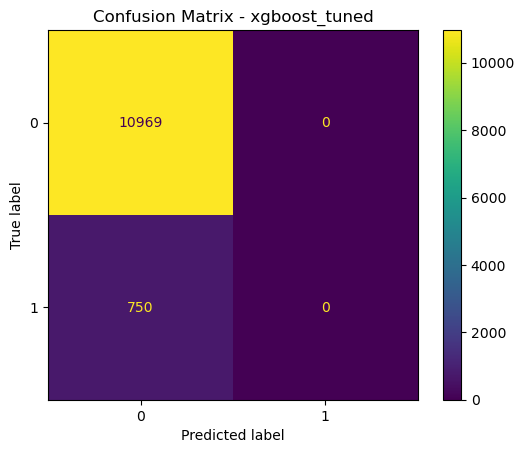

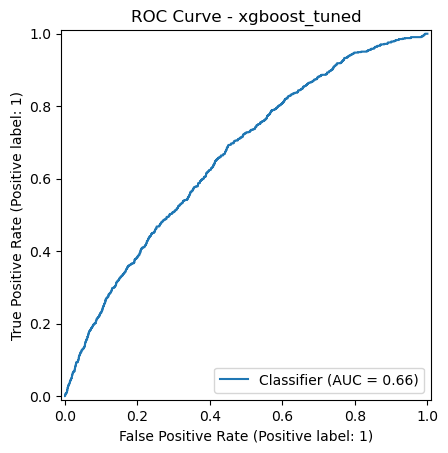

In [17]:
best_name = max(["random_forest", "xgboost"], key=lambda n: results[n]["roc_auc"])
print("Tuning:", best_name)

if best_name == "xgboost":
    base = XGBClassifier(random_state=RANDOM_SEED, eval_metric="logloss", n_jobs=-1)
    param_dist = {
        "n_estimators": [200, 300, 500],
        "max_depth": [4, 6, 8, 10],
        "learning_rate": [0.01, 0.05, 0.1],
        "subsample": [0.7, 0.85, 1.0],
        "colsample_bytree": [0.7, 0.85, 1.0],
    }
else:
    base = RandomForestClassifier(random_state=RANDOM_SEED, n_jobs=-1, class_weight="balanced")
    param_dist = {
        "n_estimators": [200, 300, 500],
        "max_depth": [8, 12, 16, None],
        "min_samples_split": [2, 5, 10],
    }

search = RandomizedSearchCV(
    base, param_dist, n_iter=10, scoring="roc_auc",
    cv=StratifiedKFold(n_splits=3, shuffle=True, random_state=RANDOM_SEED),
    random_state=RANDOM_SEED, n_jobs=-1, verbose=1
)
search.fit(X_train, y_train)
print("Best params:", search.best_params_)
print("Best CV ROC-AUC:", search.best_score_)

tuned_model = search.best_estimator_
tuned_metrics = evaluate_model(f"{best_name}_tuned", tuned_model, X_test, y_test)

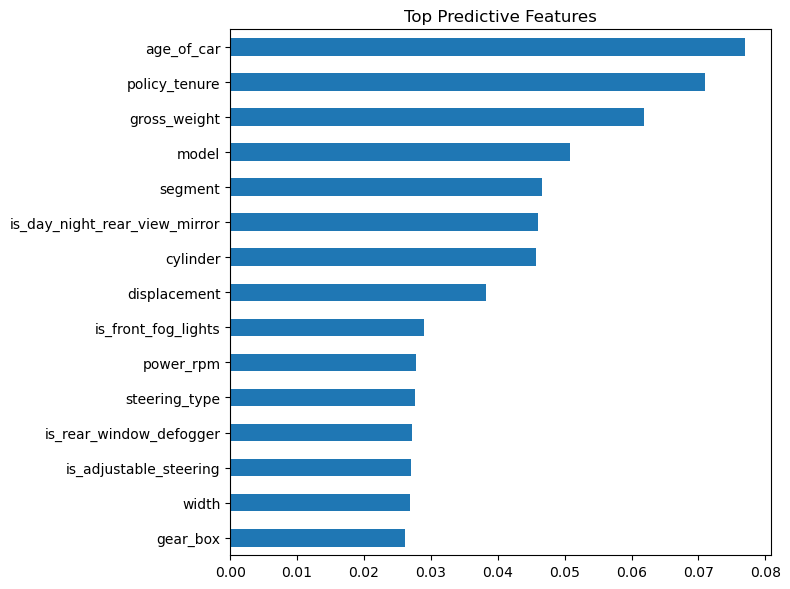

age_of_car                       0.077020
policy_tenure                    0.071023
gross_weight                     0.061831
model                            0.050722
segment                          0.046633
is_day_night_rear_view_mirror    0.046011
cylinder                         0.045731
displacement                     0.038250
is_front_fog_lights              0.028977
power_rpm                        0.027780
steering_type                    0.027675
is_rear_window_defogger          0.027117
is_adjustable_steering           0.027072
width                            0.026908
gear_box                         0.026156
dtype: float32

In [18]:
importances = pd.Series(tuned_model.feature_importances_, index=X.columns)
importances = importances.sort_values(ascending=False).head(15)

plt.figure(figsize=(8,6))
importances.sort_values().plot(kind="barh")
plt.title("Top Predictive Features")
plt.tight_layout()
plt.savefig(f"{DASHBOARD_DIR}/feature_importance.png", bbox_inches="tight")
plt.show()

importances.to_csv(f"{DASHBOARD_DIR}/top_features.csv")
importances

In [19]:
joblib.dump(tuned_model, f"{MODEL_DIR}/final_model.joblib")
joblib.dump(scaler, f"{MODEL_DIR}/scaler.joblib")
joblib.dump(encoders, f"{MODEL_DIR}/encoders.joblib")
joblib.dump(
    {"cat_cols": cat_cols, "num_cols": num_cols, "feature_order": X.columns.tolist()},
    f"{MODEL_DIR}/feature_meta.joblib"
)

with open(f"{DASHBOARD_DIR}/metrics_summary.json", "w") as f:
    json.dump(results, f, indent=2)

print("Saved model + preprocessing artifacts to", MODEL_DIR)
pd.DataFrame(results).T.sort_values("roc_auc", ascending=False)

Saved model + preprocessing artifacts to ../models


,accuracy,precision,recall,f1,roc_auc,log_loss
xgboost_tuned,0.936001,0.000000,0.000000,0.000000,0.662259,0.228566
xgboost,0.632221,0.095086,0.557333,0.162456,0.637130,0.579991
decision_tree,0.509429,0.085970,0.692000,0.152939,0.632866,0.770393
random_forest,0.713286,0.096973,0.418667,0.157472,0.631157,0.511450
logistic_regression,0.564127,0.079992,0.553333,0.139778,0.589360,0.673188


In [20]:
test_proba = tuned_model.predict_proba(X_test_final)[:, 1]
test_pred = (test_proba >= 0.5).astype(int)

submission = pd.DataFrame({
    "policy_id": test_ids.values,
    "is_claim": test_pred
})

assert list(submission.columns) == list(sample_sub.columns), "Column mismatch with sample_submission.csv"
assert len(submission) == len(sample_sub), "Row count mismatch with sample_submission.csv"

submission.to_csv(f"{MODEL_DIR}/submission.csv", index=False)
print("Saved:", f"{MODEL_DIR}/submission.csv")
print(submission["is_claim"].value_counts(normalize=True))
submission.head()

Saved: ../models/submission.csv
is_claim
0    1.0
Name: proportion, dtype: float64


,policy_id,is_claim
0,ID58593,0
1,ID58594,0
2,ID58595,0
3,ID58596,0
4,ID58597,0


In [21]:
import plotly.graph_objects as go
from sklearn.metrics import roc_curve

figs = []  # (title, figure) pairs, assembled into one HTML page at the end

# 1. Class balance
vc = df["is_claim"].value_counts().sort_index()
fig = go.Figure(go.Bar(x=["No claim", "Claim"], y=vc.values,
                       text=[f"{v:,} ({v/len(df):.1%})" for v in vc.values],
                       textposition="outside", marker_color=["#4C78A8", "#E45756"]))
fig.update_layout(title="Claim vs No-Claim (class imbalance)", yaxis_title="Policies")
figs.append(fig)

# 2. Claim rate by key categories / features
for col in ["segment", "fuel_type", "transmission_type", "ncap_rating", "airbags"]:
    if col in df.columns:
        rate = df.groupby(col)["is_claim"].mean().sort_index()
        fig = go.Figure(go.Bar(x=rate.index.astype(str), y=rate.values * 100,
                               marker_color="#F58518"))
        fig.update_layout(title=f"Claim rate (%) by {col}", xaxis_title=col,
                          yaxis_title="Claim rate (%)")
        figs.append(fig)

# 3. Claim rate by policy tenure and policyholder age (binned into 10 groups)
for col in ["policy_tenure", "age_of_policyholder", "age_of_car"]:
    if col in df.columns:
        bins = pd.qcut(df[col], 10, duplicates="drop")
        rate = df.groupby(bins, observed=True)["is_claim"].mean() * 100
        fig = go.Figure(go.Scatter(x=[str(i) for i in rate.index], y=rate.values,
                                   mode="lines+markers", line_color="#54A24B"))
        fig.update_layout(title=f"Claim rate (%) by {col} (deciles)",
                          xaxis_title=col, yaxis_title="Claim rate (%)")
        figs.append(fig)

# 4. Top predictive features
imp = importances.sort_values()
fig = go.Figure(go.Bar(x=imp.values, y=imp.index, orientation="h", marker_color="#72B7B2"))
fig.update_layout(title="Top 15 predictive features (tuned model)", height=550)
figs.append(fig)

# 5. Model comparison (ROC-AUC, recall, precision, F1)
res = pd.DataFrame(results).T
fig = go.Figure()
for metric in ["roc_auc", "recall", "precision", "f1"]:
    fig.add_bar(name=metric, x=res.index, y=res[metric])
fig.update_layout(title="Model comparison", barmode="group", yaxis_title="Score")
figs.append(fig)

# 6. ROC curve of the tuned model on the validation split
proba = tuned_model.predict_proba(X_test)[:, 1]
fpr, tpr, _ = roc_curve(y_test, proba)
fig = go.Figure()
fig.add_scatter(x=fpr, y=tpr, mode="lines", name=f"Tuned model (AUC={results[list(results)[-1]]['roc_auc']:.3f})")
fig.add_scatter(x=[0, 1], y=[0, 1], mode="lines", name="Random", line=dict(dash="dash"))
fig.update_layout(title="ROC curve (tuned model)", xaxis_title="False positive rate",
                  yaxis_title="True positive rate")
figs.append(fig)

# Assemble everything into one HTML page (Plotly JS embedded so it works offline)
parts = []
for i, f in enumerate(figs):
    parts.append(f.to_html(full_html=False, include_plotlyjs=True if i == 0 else False))
html = ("<html><head><meta charset='utf-8'><title>Car Insurance Claim Dashboard</title></head>"
        "<body style='font-family:sans-serif;max-width:1000px;margin:auto'>"
        "<h1>Car Insurance Claim Prediction - Analysis Dashboard</h1>"
        + "".join(parts) + "</body></html>")

with open(f"{DASHBOARD_DIR}/dashboard.html", "w", encoding="utf-8") as f:
    f.write(html)
print("Saved:", f"{DASHBOARD_DIR}/dashboard.html")

Saved: ../dashboard/dashboard.html
